# Лабораторная работа № 2
## Сегментация изображений с помощью U-Net

**Цель:** реализовать U-Net, обучить её на учебном наборе CARLA и повторить основные шаги на другом наборе — Penn-Fudan для выделения людей.

In [1]:
import os
import tempfile
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ.setdefault("MPLCONFIGDIR", os.path.join(tempfile.gettempdir(), "cv2-matplotlib"))
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display, Markdown
%matplotlib inline

tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.keras.utils.set_random_seed(42)

from lab2 import (conv_block, upsampling_block, unet_model, read_pair, label_colors,
                  inspect_dataset, train_model, plot_history, evaluate_model,
                  show_predictions, create_mask, worst_pairs)
from prepare_data import load_split, CARLA_CLASSES
PENN_CLASSES = ["Background", "Person"]

RETRAIN = False  # True — заново обучить обе модели с 8 фильтрами.

print("TensorFlow:", tf.__version__)
# Проверка данных и загрузка разбиения.
carla_split = load_split("carla")
penn_split = load_split("pennfudan")


TensorFlow: 2.18.1


## 1. Данные

**CARLA:** 1060 дорожных изображений и масок для 23 классов. [Источник](https://github.com/Rhythm-Adhikari1/U-Net/tree/072afa362ab567ceb8c151b18b00e05ac632bf26/data). Разбиение на обучение, валидацию и тест: 848 / 106 / 106. Близкие номера кадров объединены в группы.

**Penn-Fudan:** 170 фотографий людей и готовых масок из [публичного набора](https://github.com/swallan/PennFudanPed/tree/ec1d4583fb436b14e2062587c8b28a5018668a5e). В исходной маске каждый человек обозначен отдельным номером. Для семантической сегментации все номера людей объединены в один класс: 0 — фон, 1 — человек. Разбиение случайное с seed=42: 136 / 17 / 17 (80/10/10).

Данные подготавливаются командой `python prepare_pennfudan.py`.

CARLA {'train': 848, 'val': 106, 'test': 106}
Penn-Fudan {'train': 136, 'val': 17, 'test': 17}


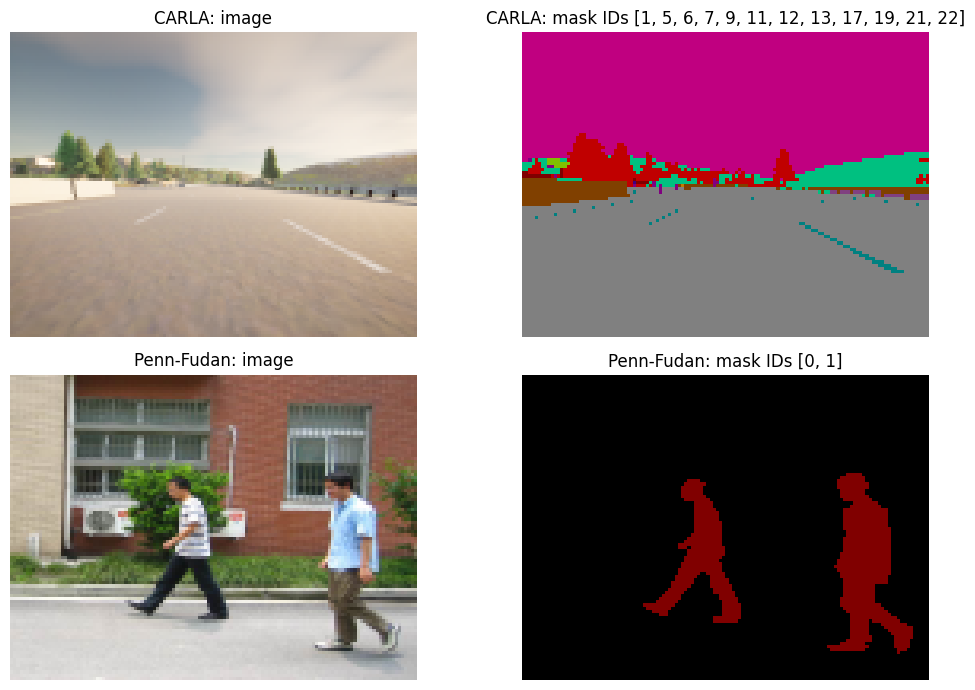

In [2]:
for name, split in [("CARLA", carla_split), ("Penn-Fudan", penn_split)]:
    print(name, {part: len(pairs) for part, pairs in split.items()})
    names = [{image.name for image, _ in pairs} for pairs in split.values()]
    assert not (names[0] & names[1] or names[0] & names[2] or names[1] & names[2])

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, (name, split, classes) in enumerate([
        ("CARLA", carla_split, CARLA_CLASSES), ("Penn-Fudan", penn_split, PENN_CLASSES)]):
    image, mask = read_pair(*split["train"][0], (96, 128), len(classes))
    axes[row, 0].imshow(image)
    axes[row, 1].imshow(label_colors(len(classes))[mask[..., 0]])
    axes[row, 0].set_title(name + ": image")
    axes[row, 1].set_title(name + ": mask IDs " + str(np.unique(mask).tolist()))
    for ax in axes[row]: ax.axis("off")
fig.tight_layout()
plt.show()


### Предобработка и распределение классов

Изображения приводятся OpenCV к **96×128**, переводятся из BGR в RGB и нормализуются в диапазон [0, 1]. Маски остаются целочисленными, их размер изменяется методом nearest neighbor. В CARLA ID класса хранится в красном канале; в Penn-Fudan ненулевые номера людей преобразованы в метку 1. Ниже показано распределение классов в обучающих данных.

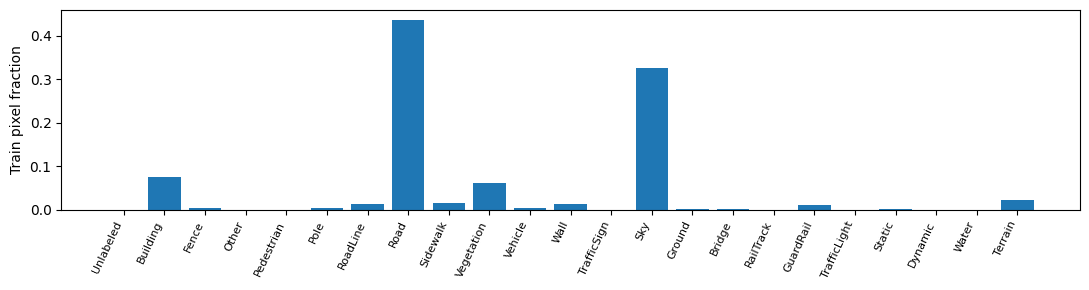

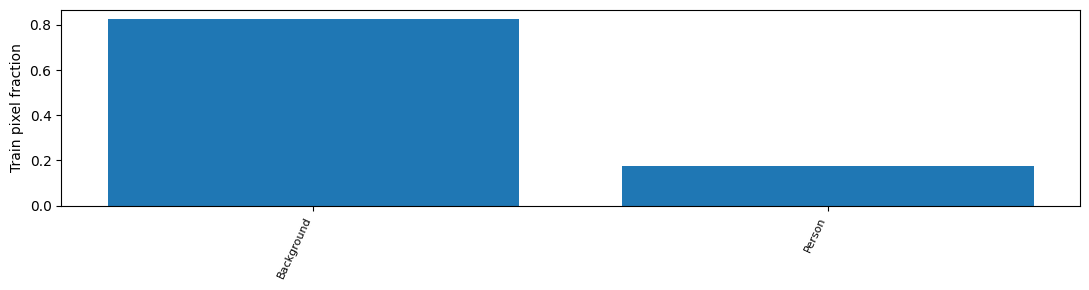

CARLA самый частый класс train: Road
Penn-Fudan самый частый класс train: Background


In [3]:
carla_stats = inspect_dataset(carla_split, "carla", (96, 128), CARLA_CLASSES)
penn_stats = inspect_dataset(penn_split, "pennfudan", (96, 128), PENN_CLASSES)
for name, stats in [("CARLA", carla_stats), ("Penn-Fudan", penn_stats)]:
    print(name, "самый частый класс train:", stats["class_names"][stats["majority_class"]])

## 2. Построение U-Net

Функции в `lab2.py` реализуют параметры из задания:
- `conv_block`: две Conv2D 3×3 с ReLU, same и he_normal; необязательный Dropout; MaxPooling 2×2;
- `upsampling_block`: Conv2DTranspose 3×3 со stride=2, объединение `[up, skip]`, две Conv2D;
- `unet_model`: пять блоков encoder, четыре decoder, Dropout=0.3 в четвёртом и пятом encoder; последний encoder без pooling; на выходе Conv2D 1×1 с числом каналов по числу классов.

Skip connections возвращают decoder признаки высокого разрешения. Выход содержит logits, поэтому используется `SparseCategoricalCrossentropy(from_logits=True)`, а не отдельный softmax перед loss.


In [4]:
inputs = tf.keras.layers.Input((96, 128, 3))
next_layer, skip = conv_block(inputs, 32)
assert tuple(next_layer.shape) == (None, 48, 64, 32)
assert tuple(skip.shape) == (None, 96, 128, 32)

small = tf.keras.layers.Input((12, 16, 256))
contractive = tf.keras.layers.Input((24, 32, 128))
up = upsampling_block(small, contractive, 32)
assert tuple(up.shape) == (None, 24, 32, 32)

reference_model = unet_model()  # Полная ширина из задания: 32 начальных фильтра.
assert reference_model.output_shape == (None, 96, 128, 23)
print("Параметров в варианте n_filters=32:", reference_model.count_params())
print("Все 23 цвета различаются:", len(np.unique(label_colors(23), axis=0)) == 23)
del reference_model
training_model = unet_model(n_filters=8)
training_model.summary()
del training_model


Параметров в варианте n_filters=32: 8640471
Все 23 цвета различаются: True


Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 96, 128,   │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 96, 128,   │        224 │ input_layer_4[0]… │
│                     │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 96, 128,   │        584 │ conv2d_24[0][0]   │
│                     │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 48, 64, 8) │          0 │ conv2d_25[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 48, 64,    │      1,168 │ max_pooling2d_5[… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 48, 64,    │      2,320 │ conv2d_26[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 24, 32,    │          0 │ conv2d_27[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 24, 32,    │      4,640 │ max_pooling2d_6[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 24, 32,    │      9,248 │ conv2d_28[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 12, 16,    │          0 │ conv2d_29[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 12, 16,    │     18,496 │ max_pooling2d_7[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 12, 16,    │     36,928 │ conv2d_30[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 12, 16,    │          0 │ conv2d_31[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 6, 8, 64)  │          0 │ dropout_2[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 6, 8, 128) │     73,856 │ max_pooling2d_8[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 6, 8, 128) │    147,584 │ conv2d_32[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 6, 8, 128) │          0 │ conv2d_33[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_5  │ (None, 12, 16,    │     73,792 │ dropout_3[0][0] 

 Total params: 540,999 (2.06 MB)

 Trainable params: 540,999 (2.06 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Обучение на CARLA

Использую Adam, batch size 8 и 40 эпох. Для обучения базовой модели на CPU начальное число фильтров равно 8; все блоки и skip connections сохранены. Модель выбирается по минимальному validation loss. Графики показывают изменение loss и accuracy на обучении и валидации.

carla: загружен выполненный эксперимент (40 эпох), лучшая эпоха 18


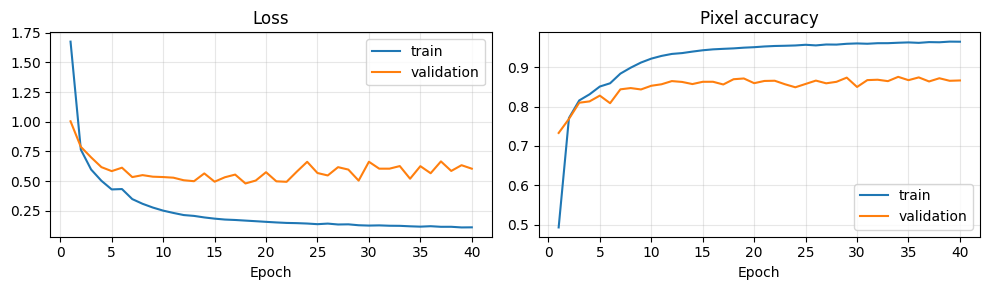

In [5]:
EPOCHS = 40
N_FILTERS = 8

carla_model, carla_history = train_model(
    carla_split, "carla", size=(96, 128), n_classes=23,
    epochs=EPOCHS, n_filters=N_FILTERS, reuse_existing=not RETRAIN)
plot_history(carla_history, "carla")


### Оценка CARLA

Pixel accuracy — доля правильных пикселей. IoU класса — пересечение настоящей и предсказанной области, делённое на объединение. Mean IoU усредняет классы, поэтому лучше показывает ошибки на небольших объектах. Класс без истинных и предсказанных пикселей не включается в среднее; его IoU помечается как отсутствующий.

Для сравнения использую простой baseline: всегда предсказывать самый частый **обучающий** класс. Он не использует метки теста для выбора класса. Если U-Net не превосходит такой baseline, одной высокой accuracy было бы недостаточно.


CARLA: accuracy=0.8832, mean IoU=0.2599
Baseline: {'class': 7, 'accuracy': 0.37307221034787735, 'mean_iou': 0.02072623390821541}


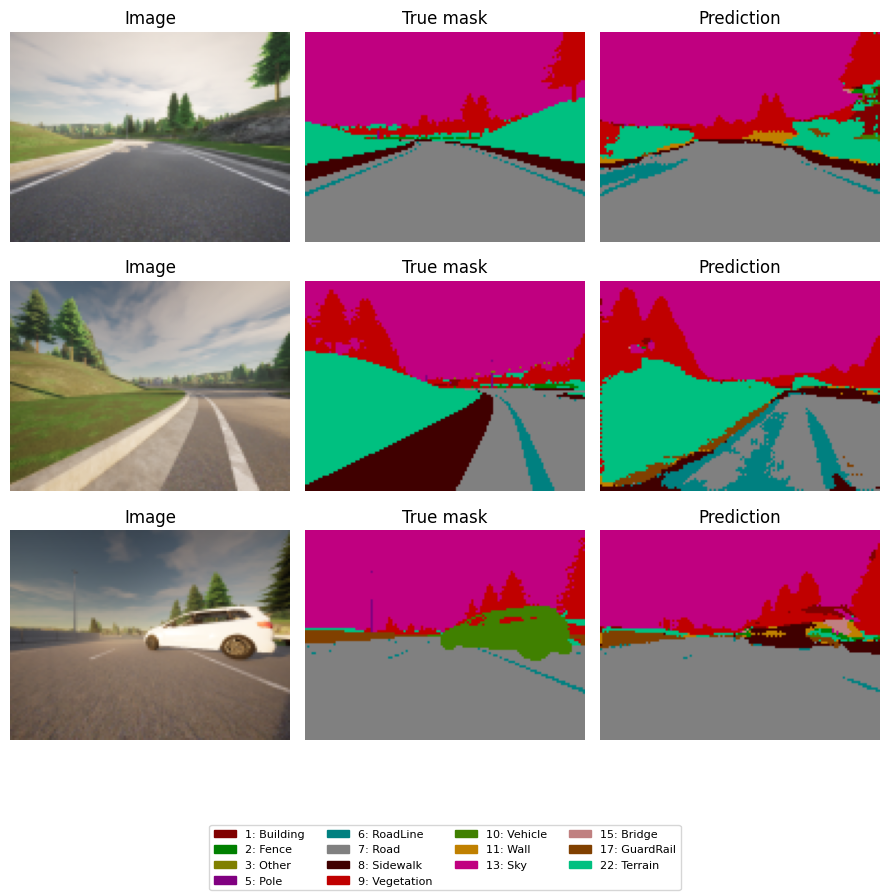

In [6]:
carla_scores = evaluate_model(
    carla_model, carla_split["test"], (96, 128), 23, "carla",
    baseline_class=carla_stats["majority_class"], class_names=CARLA_CLASSES)
print(f"CARLA: accuracy={carla_scores['accuracy']:.4f}, mean IoU={carla_scores['mean_iou']:.4f}")
print("Baseline:", {key: carla_scores["majority_baseline"][key] for key in ["class", "accuracy", "mean_iou"]})
show_predictions(carla_model, carla_split["test"], (96, 128), 23,
                 "carla", class_names=CARLA_CLASSES)


### Разбор ошибок CARLA

Посмотрим поклассовые IoU и два тестовых кадра с наименьшим средним IoU. Мелкие и редкие объекты распознаются хуже крупных областей.

Building: 30785 пикселей, IoU = 0.501
Fence: 6594 пикселей, IoU = 0.003
Other: 454 пикселей, IoU = 0.000
Pedestrian: 177 пикселей, IoU = 0.000
Pole: 1841 пикселей, IoU = 0.001
RoadLine: 33749 пикселей, IoU = 0.354
Road: 485937 пикселей, IoU = 0.910
Sidewalk: 49979 пикселей, IoU = 0.409
Vegetation: 121194 пикселей, IoU = 0.676
Vehicle: 12947 пикселей, IoU = 0.076
Wall: 4 пикселей, IoU = 0.000
TrafficSign: 199 пикселей, IoU = 0.000
Sky: 450261 пикселей, IoU = 0.968
Bridge: 385 пикселей, IoU = 0.000
GuardRail: 7328 пикселей, IoU = 0.443
Static: 7067 пикселей, IoU = 0.000
Dynamic: 2680 пикселей, IoU = 0.000
Terrain: 90947 пикселей, IoU = 0.597


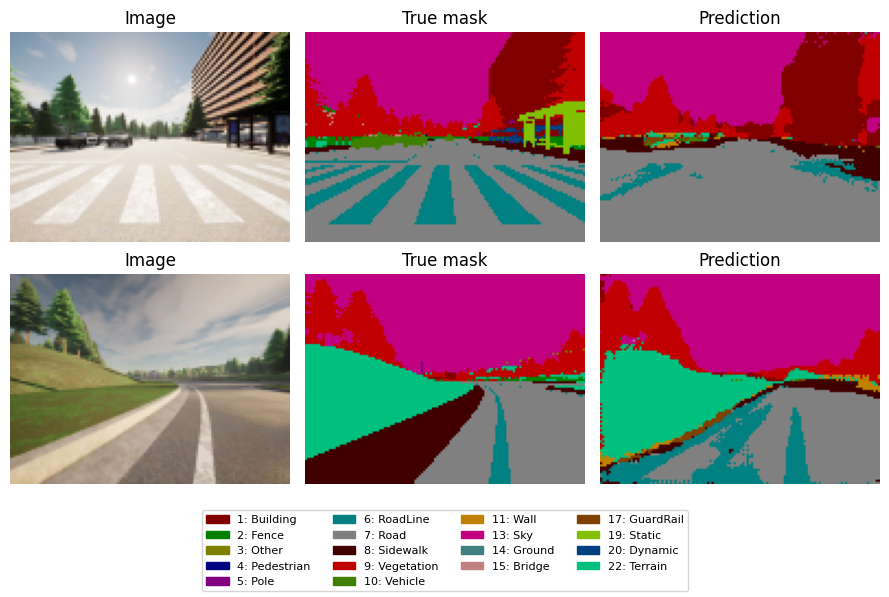

In [7]:
for label, pixels, iou in zip(CARLA_CLASSES, carla_scores["class_pixels"], carla_scores["iou_per_class"]):
    if pixels:
        print(f"{label}: {pixels} пикселей, IoU = {iou:.3f}")
selected = worst_pairs(carla_scores, carla_split["test"])
show_predictions(carla_model, selected, (96, 128), 23, "carla_worst", count=2, class_names=CARLA_CLASSES)

## 4. Второй набор: сегментация людей

Повторяю обучение той же архитектуры U-Net на Penn-Fudan. На выходе два класса: фон и человек. Использую изображения и готовые маски из набора, а не разметку собственных фотографий. Для второго эксперимента достаточно 20 эпох: графики и тестовые предсказания показывают фактический результат.

pennfudan: загружен выполненный эксперимент (20 эпох), лучшая эпоха 18


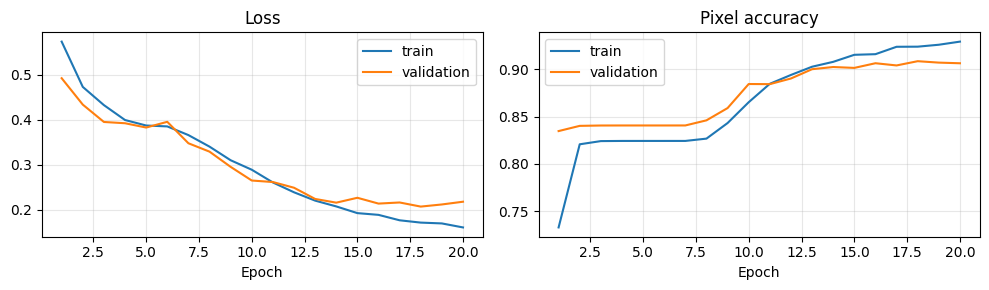

Penn-Fudan: accuracy=0.8967, mean IoU=0.6926
IoU человека: 0.5005
Baseline: {'class': 0, 'accuracy': 0.8355258118872549, 'mean_iou': 0.41776290594362747}


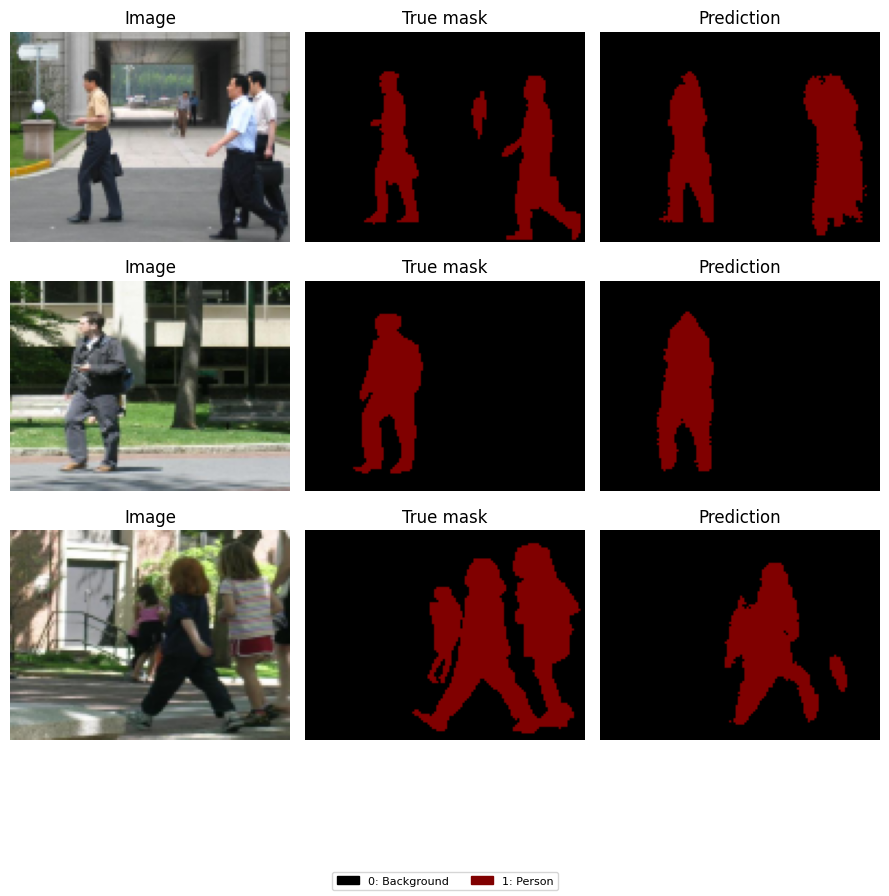

In [8]:
penn_model, penn_history = train_model(
    penn_split, "pennfudan", size=(96, 128), n_classes=2,
    epochs=20, n_filters=8, reuse_existing=not RETRAIN)
plot_history(penn_history, "pennfudan")
penn_scores = evaluate_model(
    penn_model, penn_split["test"], (96, 128), 2, "pennfudan",
    baseline_class=penn_stats["majority_class"], class_names=PENN_CLASSES)
print(f"Penn-Fudan: accuracy={penn_scores['accuracy']:.4f}, mean IoU={penn_scores['mean_iou']:.4f}")
print(f"IoU человека: {penn_scores['iou_per_class'][1]:.4f}")
print("Baseline:", {key: penn_scores["majority_baseline"][key] for key in ["class", "accuracy", "mean_iou"]})
show_predictions(penn_model, penn_split["test"], (96, 128), 2,
                 "pennfudan", class_names=PENN_CLASSES)

## 5. Итоги

Сравнение с baseline, который всегда предсказывает самый частый класс обучающей выборки. Числа CARLA и Penn-Fudan не являются прямым сравнением качества: наборы содержат разные классы и изображения.

In [9]:
rows = ["| Набор | Тестовых изображений | Accuracy | Mean IoU | Baseline mIoU |", "| --- | ---: | ---: | ---: | ---: |"]
for name, scores in [("CARLA", carla_scores), ("Penn-Fudan", penn_scores)]:
    rows.append(f"| {name} | {scores['test_images']} | {scores['accuracy']:.3f} | {scores['mean_iou']:.3f} | {scores['majority_baseline']['mean_iou']:.3f} |")
display(Markdown("\n".join(rows)))

| Набор | Тестовых изображений | Accuracy | Mean IoU | Baseline mIoU |
| --- | ---: | ---: | ---: | ---: |
| CARLA | 106 | 0.883 | 0.260 | 0.021 |
| Penn-Fudan | 17 | 0.897 | 0.693 | 0.418 |

На CARLA хорошо выделяются крупные области, но качество редких классов невысокое. На Penn-Fudan модель находит людей, однако пропускает мелкие детали и иногда объединяет соседние фигуры. Тест второго набора содержит только 17 изображений, поэтому оценка приблизительная.

### Дополнительный вариант U-Net для CARLA

Для CARLA также сохранён эксперимент с 32 начальными фильтрами и взвешенной функцией потерь. Он приведён как дополнительное сравнение; ширина сети и функция потерь менялись одновременно. Тест уже использовался при анализе первой модели, поэтому сравнение исследовательское.

Accuracy на CARLA: {'8': 0.8831664271324685, '32': 0.8860354633451258}
Mean IoU на CARLA: {'8': 0.2598822375229576, '32': 0.2472643331353889}


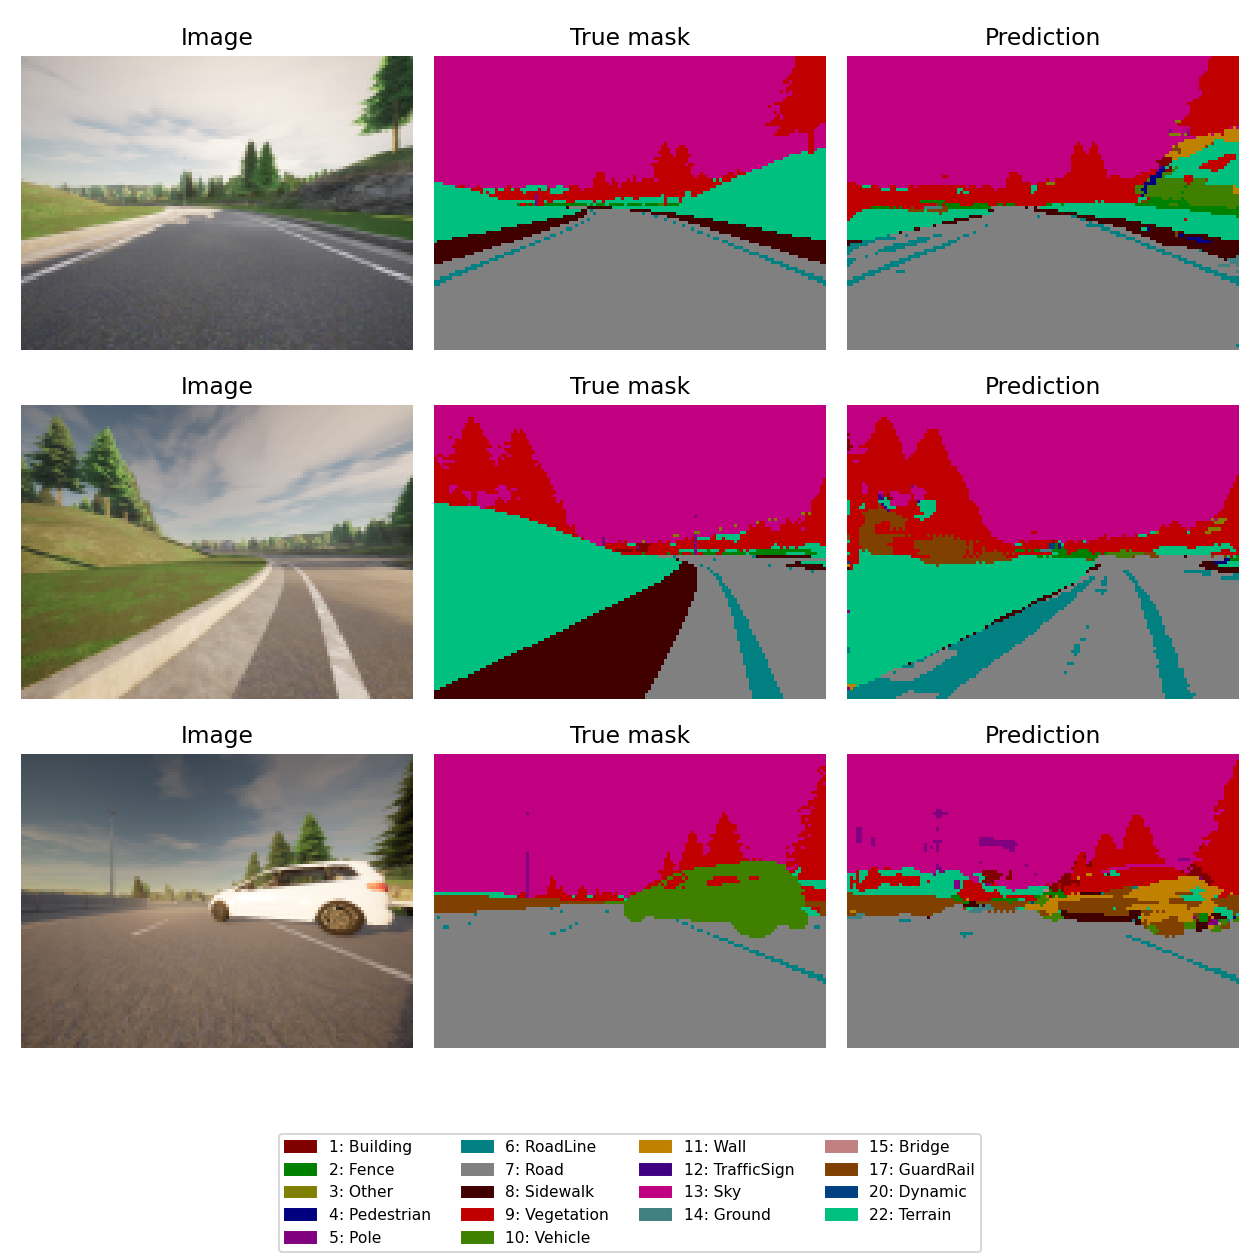

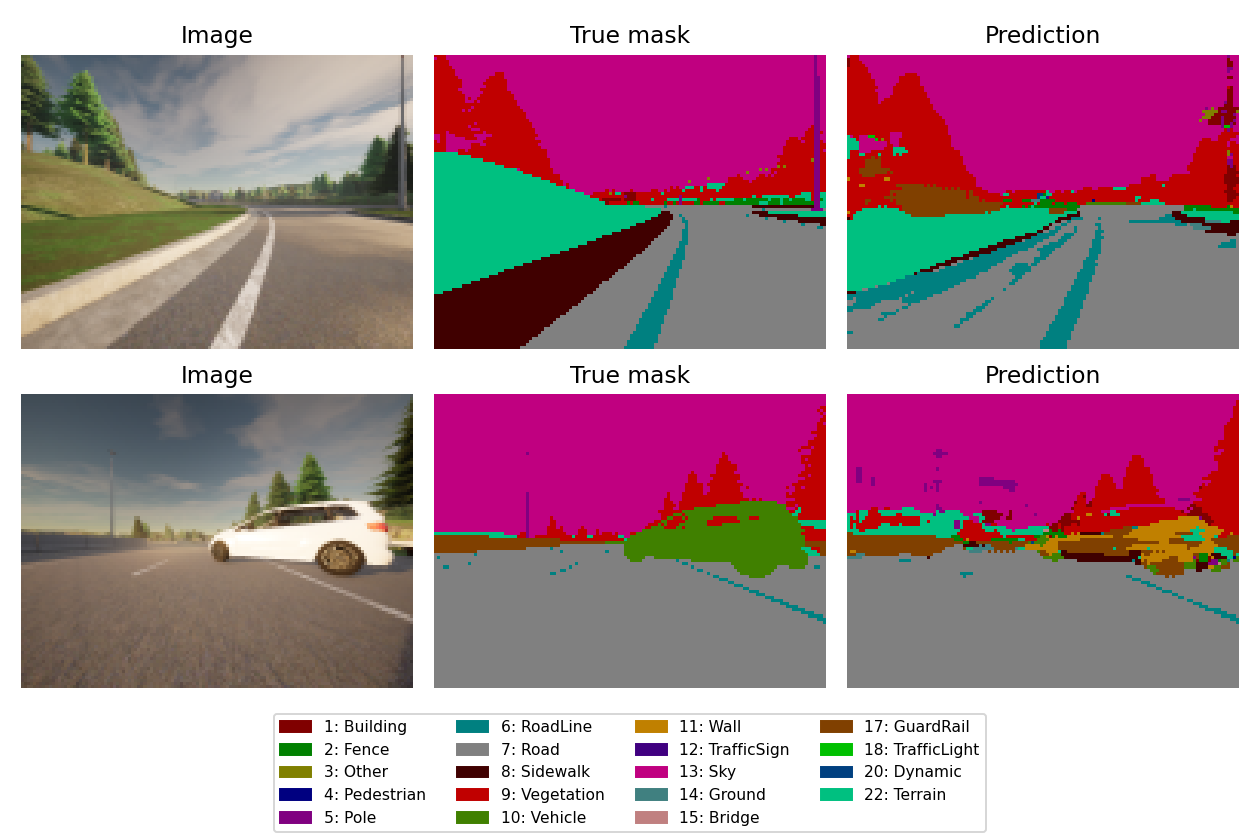

In [10]:
from IPython.display import Image
comparison = json.loads(Path("results/experiment_32/carla_comparison.json").read_text())
print("Accuracy на CARLA:", comparison["test_accuracy"])
print("Mean IoU на CARLA:", comparison["test_mean_iou"])
display(Image(filename="results/experiment_32/carla_predictions.png"))
display(Image(filename="results/experiment_32/carla_worst_predictions.png"))

### Проверка CARLA на другом наборе кадров

Дополнительно использованы 223 кадра из [другого набора CARLA](https://github.com/cpow-89/carla_image_segmentation_dataset/tree/aa0eb00150f3fda6f7950f097baa145890717979). Для него учитываются классы 1–12; неразмеченные пиксели исключены. Это другие условия оценки, поэтому значения не следует напрямую сравнивать с результатом по 23 классам.

Фильтров: 8; mean IoU: 0.146
Фильтров: 32; mean IoU: 0.247


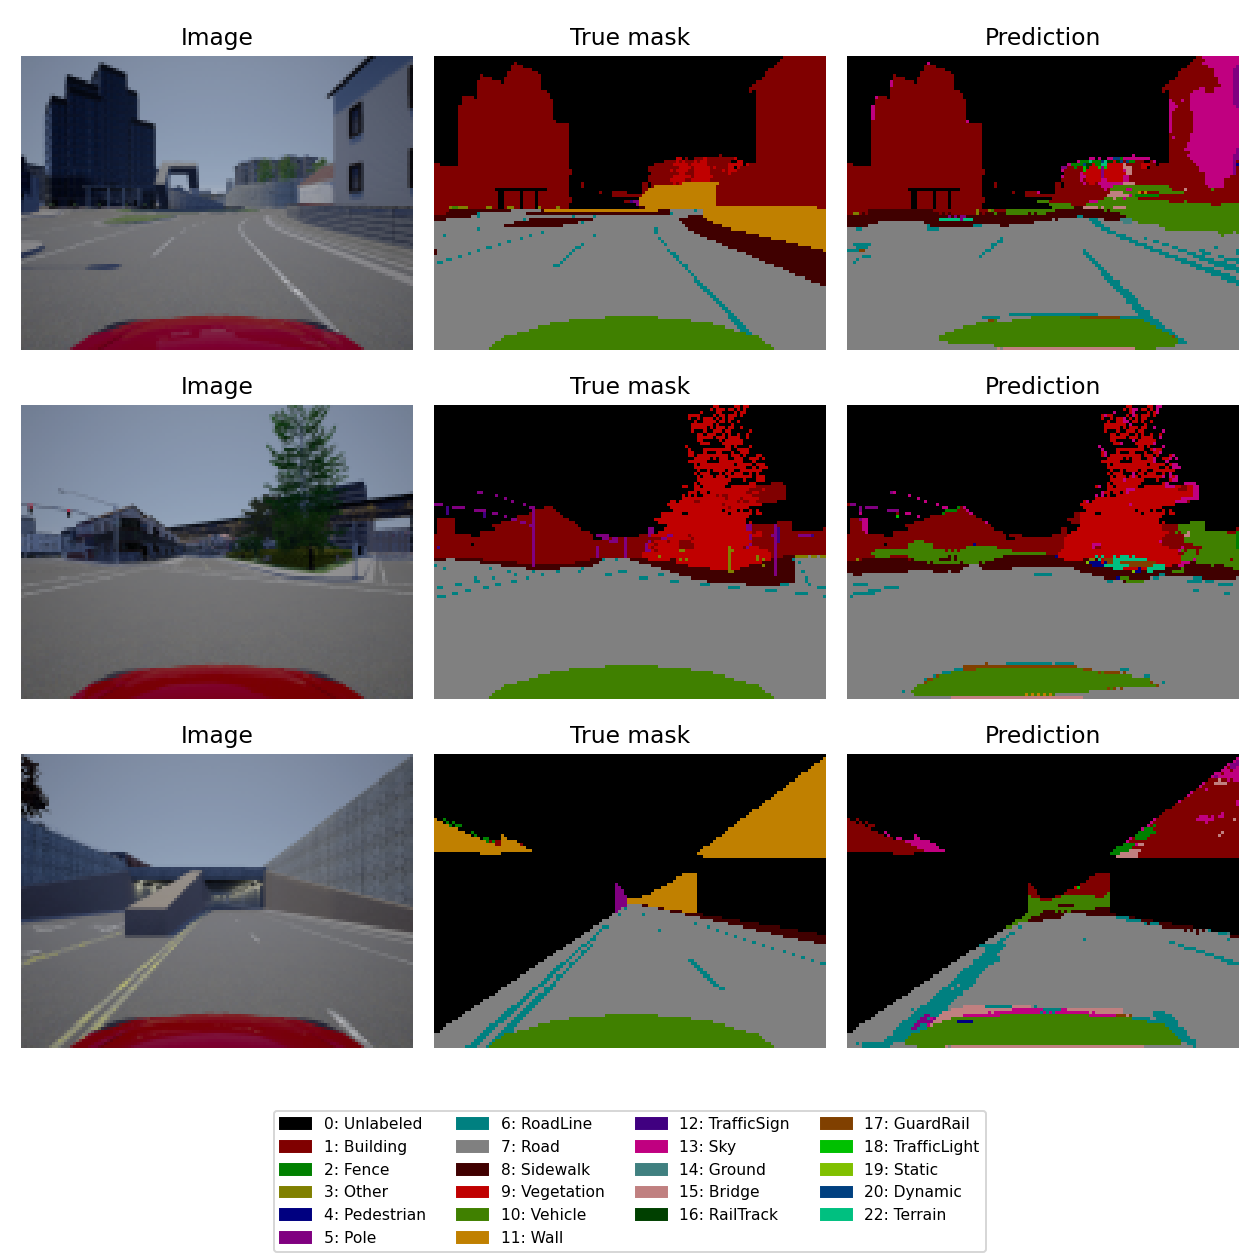

In [11]:
external = json.loads(Path("results/experiment_32/carla_external_metrics.json").read_text())
for width in ["8", "32"]:
    print(f"Фильтров: {width}; mean IoU: {external['models'][width]['mean_iou']:.3f}")
display(Image(filename="results/experiment_32/carla_external_predictions.png"))

## 6. Собственные фотографии

Для дополнительной визуальной проверки применяю обученные модели к четырём собственным фотографиям. Сначала показаны две модели CARLA, затем модель выделения людей. Эталонных масок для этих снимков нет, поэтому IoU для них не рассчитывается. На некоторых снимках модель ошибочно относит к людям части фона; результат показывает ограничения переноса на новые сцены.

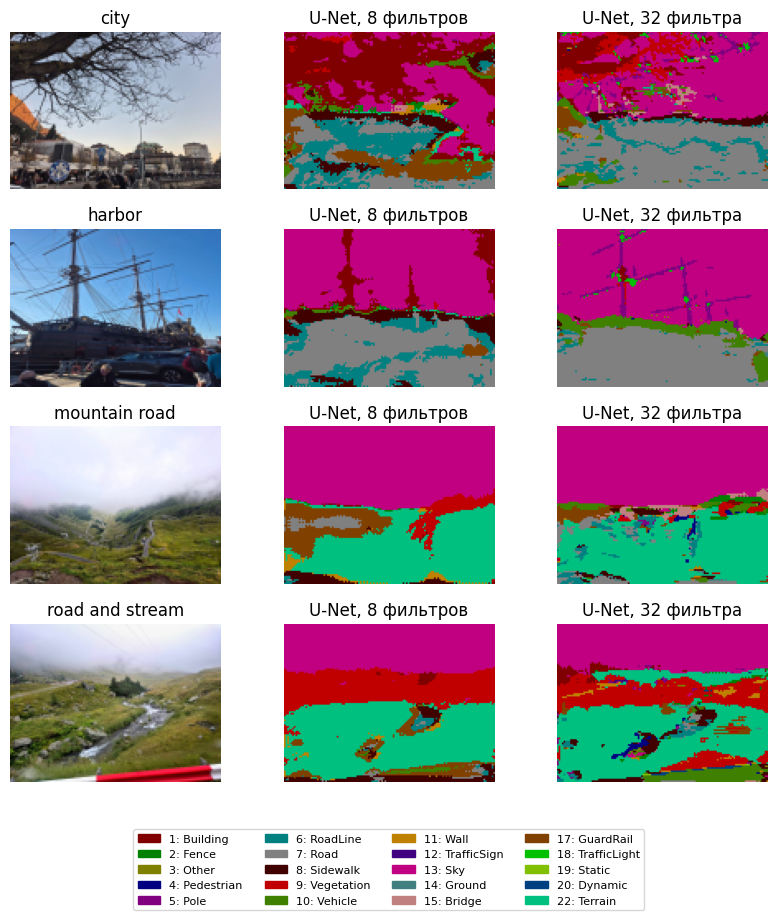

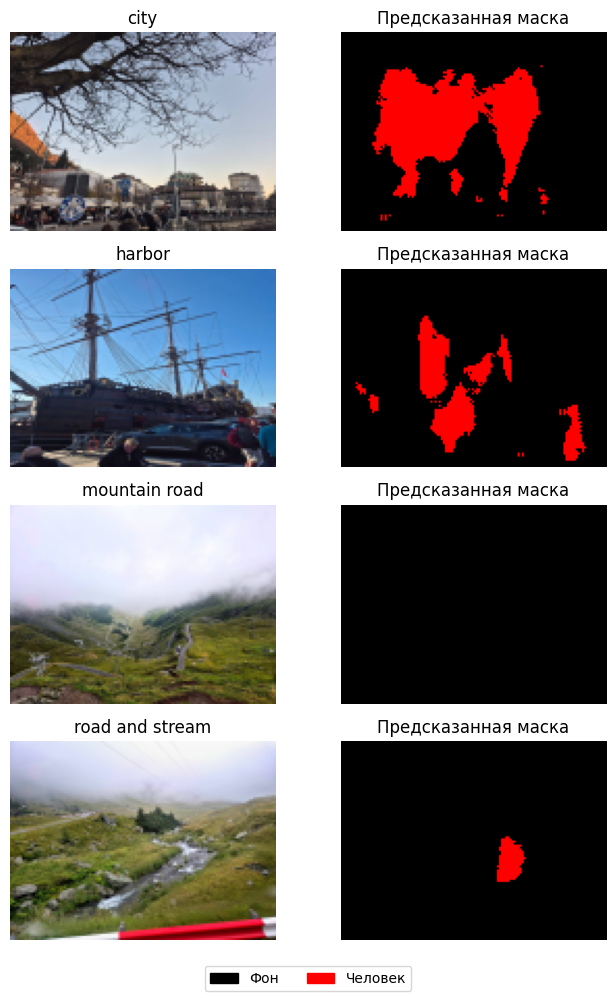

In [12]:
from own_photos import show_own_photos, show_people_photos
_ = show_own_photos("carla")
_ = show_people_photos()